Imports (DBG-KAN is embedded below, so no extra installation is needed)

In [1]:
import os
import math
import time
from typing import List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Load and clean the dataset

In [2]:
# same local path as the original notebook, with fallbacks for Colab / the current folder
_candidates = ["C:/Users/Benyamin/Documents/KAN/FinalDataNN.xlsx", "/content/FinalDataNN.xlsx", "FinalDataNN.xlsx"]
excel_path = next((p for p in _candidates if os.path.exists(p)), _candidates[0])
df = pd.read_excel(excel_path)

df_cleaned = df.dropna(subset=["P", "Y", "Ptest", "Ytest"])

P_train = df_cleaned["P"].values.astype("float32")
Y_train = df_cleaned["Y"].values.astype("float32")
P_test = df_cleaned["Ptest"].values.astype("float32")
Y_test = df_cleaned["Ytest"].values.astype("float32")

print(f"Train set size: {len(P_train)} samples")
print(f"Test set size: {len(P_test)} samples")

Train set size: 1072 samples
Test set size: 1072 samples


Hyper-parameters

In [12]:
# ---- DBG-KAN hyper-parameters (defaults follow hoangthangta/All-KAN: run.py / DBG_KAN_Layer) ----
Grid_Size       = 5
Spline_Order    = 3
Base_Activation = "silu"        # run.py default
Basis_Type      = "both"        # "b_spline" | "rbf" | "both"  (run.py default = "both")
Gate_Type       = "decoupled"   # "coupled" | "decoupled" | "none"
                                # NOTE: run.py's default "shared_head" is not handled by DBG_KAN_Layer.forward (ValueError)
Use_Base_Update = False         # run.py default (the --use_base_update flag is off)

# LayerNorm in DBG_KAN_Layer is applied to the per-feature gated outputs, AFTER the basis expansion.
# For the embedding of a constant P chunk all five outputs are identical -> LayerNorm gives 0 and the P level is lost,
# so the embedding layer uses no norm; the recurrent cell keeps the repo default.
Embed_Norm_Type = ""
Cell_Norm_Type  = "layer"

# Grid ranges (repo default is [-2, 2]; the DBG_KAN wrapper does not expose it, the layer does)
Cell_Grid_Min, Cell_Grid_Max = -1.0, 1.0     # recurrent cell only sees tanh-bounded inputs in [-1, 1]
Embed_Margin = 0.1                            # embedding grid covers [min(P)-margin, max(P)+margin] of the training data
Embed_Grid_Min = float(P_train.min()) - Embed_Margin
Embed_Grid_Max = float(P_train.max()) + Embed_Margin

# ---- recurrent-wrapper option (not part of the repo) ----
Use_Tanh_Bound  = True   # h_t = tanh(DBG([e_t ; h_{t-1}])), e_t = tanh(DBG(chunk)): keeps inputs inside the basis grid

# ---- training / data hyper-parameters (same as the original notebook) ----
Batch_Size  = 32
Context_Len = 120
Pred_Len    = 20
H_Dims      = 32
N_Epochs    = 1500
Learning_Rate = 3e-4
Weight_Decay  = 0.01     # AdamW default, made explicit
Seq_Step = 5

print("Embedding grid range:", (Embed_Grid_Min, Embed_Grid_Max))

Embedding grid range: (-0.09913075601216406, 1.1)


Displaying Time Series

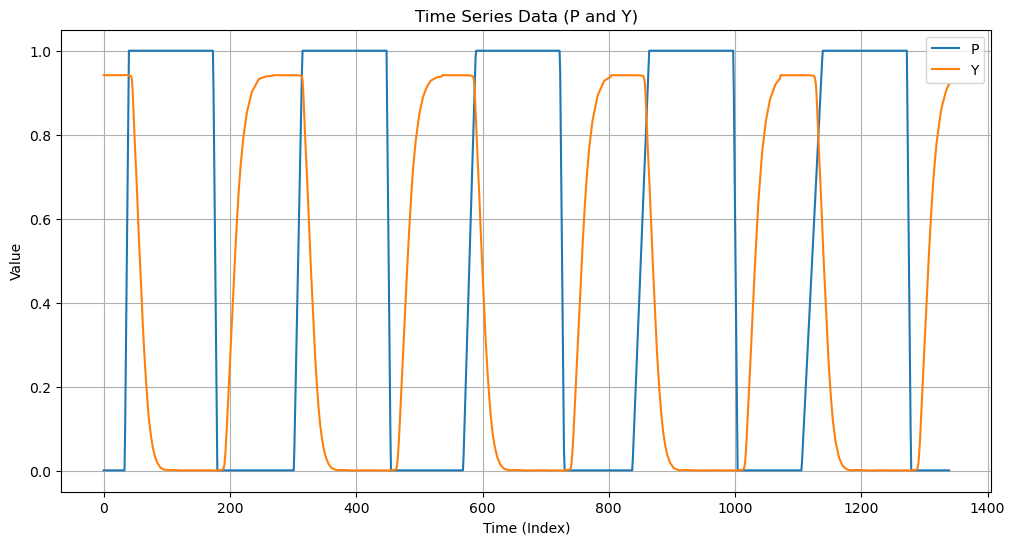

In [4]:
time_series_data_P = df["P"]
time_series_data_Y = df["Y"]

plt.figure(figsize=(12, 6))
plt.plot(time_series_data_P, label="P")
plt.plot(time_series_data_Y, label="Y")
plt.title("Time Series Data (P and Y)")
plt.xlabel("Time (Index)")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

Sliding-window dataset (P → Y)

In [13]:
class PairedTimeSeriesDataset(Dataset):
    def __init__(self, x_series, y_series, context_len=Context_Len, pred_len=Pred_Len):
        self.x = torch.tensor(x_series, dtype=torch.float32)
        self.y = torch.tensor(y_series, dtype=torch.float32)
        self.context_len = context_len
        self.pred_len = pred_len
        self.total_len = context_len + pred_len
        self.n_samples = max(len(self.x) - self.total_len + 1, 0)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        x_win = self.x[idx: idx + self.context_len]
        y_win = self.y[idx + self.context_len: idx + self.total_len]
        return x_win, y_win

train_dataset = PairedTimeSeriesDataset(P_train, Y_train)
test_dataset = PairedTimeSeriesDataset(P_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=Batch_Size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=Batch_Size, shuffle=False)

print(f"Train windows: {len(train_dataset)}")
print(f"Test windows: {len(test_dataset)}")

Train windows: 933
Test windows: 933


DBG-KAN layer (verbatim from hoangthangta/All-KAN, `models/dbg_kan.py`)

In [14]:
#import math
#import numpy as np
#import torch
#import torch.nn as nn
#import torch.nn.functional as F

class RadialBasisFunction(nn.Module):
    """
    Implements a Radial Basis Function (RBF) layer.
    """
    def __init__(
        self,
        grid_min: float = -2.0,  
        grid_max: float = 2.0,  
        num_grids: int = 8,  # n_center
        denominator: float = None,  # larger denominators lead to smoother basis
    ):
        super().__init__()
        grid = torch.linspace(grid_min, grid_max, num_grids)
        self.grid = torch.nn.Parameter(grid, requires_grad=False)
        self.denominator = denominator or (grid_max - grid_min) / (num_grids - 1)

    def forward(self, x):
        return torch.exp(-((x[..., None] - self.grid) / self.denominator) ** 2)

class DBG_KAN_Layer(nn.Module):

    activation_fns = {
        "softplus": F.softplus,
        "sigmoid": torch.sigmoid,
        "silu": F.silu,
        "relu": F.relu,
        "leaky_relu": F.leaky_relu,
        "elu": F.elu,
        "gelu": F.gelu,
        "selu": F.selu,
        "tanh": torch.tanh,
    }

    def __init__(
        self,
        input_dim,
        output_dim,
        grid_size=5,
        spline_order=3,
        base_activation="silu",
        grid_min=-2.0,
        grid_max=2.0,
        norm_type="layer",
        basis_type="both",
        gate_type="coupled",
        use_base_update=False,
    ):
        super().__init__()

        self.basis_type = basis_type
        self.gate_type = gate_type
        self.use_base_update = use_base_update
        self.input_dim  = input_dim
        self.output_dim = output_dim
        self.spline_order = spline_order
        self.grid_size = grid_size

        # activation
        if base_activation in [None, "none", "identity", ""]:
            self.base_activation = nn.Identity()
        else:
            if base_activation not in self.activation_fns:
                raise ValueError(f"Unknown activation: {base_activation}")
            self.base_activation = self.activation_fns[base_activation]

        self.norm = self._get_norm(norm_type, input_dim)

        # grid
        h = (grid_max - grid_min) / grid_size
        grid = (
            torch.arange(-spline_order, grid_size + spline_order + 1) * h
            + grid_min
        ).expand(input_dim, -1).contiguous()
        
        #self.grid = nn.Parameter(grid, requires_grad=True)
        self.register_buffer("grid", grid)

        self.rbf = RadialBasisFunction(
            grid_min, grid_max, grid_size + spline_order
        )
        
        self.output_linear = nn.Linear(input_dim, output_dim, bias=True)
        nn.init.kaiming_uniform_(self.output_linear.weight, a=math.sqrt(5))

        self.basis_mixer = nn.Linear(grid_size + spline_order, grid_size + spline_order, bias=True)

        if gate_type == "coupled":
            self.head = nn.Linear(grid_size + spline_order, 2)
        elif gate_type == "decoupled":
            self.value_head = nn.Linear(grid_size + spline_order, 1, bias=True)
            self.gate_head = nn.Linear(grid_size + spline_order, 1, bias=True)

        if use_base_update:
            self.base_linear = nn.Linear(input_dim, output_dim, bias=True)

        self.k = grid_size + spline_order
        
        self.alpha = nn.Parameter(torch.tensor(1.0))
        self.beta = nn.Parameter(torch.tensor(1.0))
        #self.alpha = nn.Parameter(torch.zeros(1, input_dim, 1))

    def _get_norm(self, norm_type, dim):
        if norm_type == "layer":
            return nn.LayerNorm(dim)
        elif norm_type == "batch":
            return nn.BatchNorm1d(dim)
        return nn.Identity()

    def b_splines(self, x: torch.Tensor):
        """
        Compute the B-spline bases for the given input tensor.
        """
        assert x.dim() == 2 and x.size(1) == self.input_dim

        grid: torch.Tensor = self.grid  # (input_dim, grid_size + 2 * spline_order + 1)
        x = x.unsqueeze(-1)
        bases = ((x >= grid[:, :-1]) & (x < grid[:, 1:])).to(x.dtype)

        for k in range(1, self.spline_order + 1):
            bases = (
                (x - grid[:, : -(k + 1)]) / (grid[:, k:-1] - grid[:, : -(k + 1)]) * bases[:, :, :-1]
            ) + (
                (grid[:, k + 1:] - x) / (grid[:, k + 1:] - grid[:, 1:(-k)]) * bases[:, :, 1:]
            )

        assert bases.size() == (
            x.size(0),
            self.input_dim,
            self.grid_size + self.spline_order,
        )
        return bases.contiguous()


    
    def forward(self, x):
        x_ori = x
        #x = self.norm(x)

        if self.basis_type == "b_spline": x = self.b_splines(x)
        elif self.basis_type == "rbf": x = self.rbf(x)
        else: x = self.b_splines(x) + self.rbf(x)
        
        h = self.basis_mixer(x)           

        if self.gate_type == "coupled":
            v, g = self.head(h).chunk(2, dim=-1)
        elif self.gate_type == "decoupled":
            v = self.value_head(h)
            g = self.gate_head(h) 
        elif (self.gate_type == "none"):
            out = h.sum(dim=-1)
        else:
            raise ValueError(f"Unknown gate_type: '{self.gate_type}'. ""Expected one of: 'coupled', 'decoupled', 'none'.")
        
        if self.gate_type in ["coupled", "decoupled"]: 
            #out = (v * torch.sigmoid(g)).squeeze(-1) 
            out = (v * F.silu(g)).squeeze(-1) 

        out = self.norm(out)
        out = self.output_linear(self.base_activation(out))
        if self.use_base_update:
            out = out + self.base_linear(self.base_activation(x_ori))
        
        return out

# Dynamic Basis-Gated KAN
class DBG_KAN(nn.Module):
   
    def __init__(
        self,
        layers_hidden,
        grid_size=5,
        spline_order=3,
        base_activation='silu',
        grid_min=-2.0,
        grid_max=2.0,
        norm_type='layer',
        basis_type="both",
        gate_type="shared_head",
        use_base_update=True,
    ):
        super().__init__()
        self.grid_size = grid_size
        self.spline_order = spline_order
        self.layers = nn.ModuleList()

        for input_dim, output_dim in zip(layers_hidden, layers_hidden[1:]):
            self.layers.append(
                DBG_KAN_Layer(
                    input_dim,
                    output_dim,
                    grid_size=grid_size,
                    spline_order=spline_order,
                    base_activation=base_activation,
                    norm_type=norm_type,
                    basis_type = basis_type,
                    gate_type = gate_type,
                    use_base_update = use_base_update 
                )
            )

    def forward(self, x: torch.Tensor):
        for layer in self.layers:
            x = layer(x)
        return x


DBG-KAN recurrent blocks

In [15]:
def make_dbg_layer(input_dim, output_dim, grid_min, grid_max, norm_type):
    """Single DBG_KAN_Layer configured from the hyper-parameter cell."""
    return DBG_KAN_Layer(
        input_dim,
        output_dim,
        grid_size=Grid_Size,
        spline_order=Spline_Order,
        base_activation=Base_Activation,
        grid_min=grid_min,
        grid_max=grid_max,
        norm_type=norm_type,
        basis_type=Basis_Type,
        gate_type=Gate_Type,
        use_base_update=Use_Base_Update,
    )


class DBGKANRNNCell(nn.Module):
    """
    A genuinely recurrent KAN cell: the hidden-state update
        h_t = tanh( DBG-KAN([x_t ; h_{t-1}]) )
    is computed by a DBG-KAN layer instead of the Linear + activation used by a vanilla RNN cell.
    The tanh keeps h_t inside the basis grid (outside it the B-spline / RBF bases vanish).
    """
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.kan = make_dbg_layer(input_size + hidden_size, hidden_size,
                                  Cell_Grid_Min, Cell_Grid_Max, Cell_Norm_Type)

    def forward(self, x_t, h_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        h_t = self.kan(combined)
        return torch.tanh(h_t) if Use_Tanh_Bound else h_t


class DBGKANRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = DBGKANRNNCell(input_size, hidden_size)
        self.readout = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        batch_size, seq_len, _ = x.shape
        if h0 is None:
            h_t = torch.zeros(batch_size, self.hidden_size, device=x.device, dtype=x.dtype)
        else:
            h_t = h0

        outputs = []
        for t in range(seq_len):
            h_t = self.cell(x[:, t, :], h_t)   # <-- recurrence: h_t depends on h_{t-1}
            outputs.append(self.readout(h_t).unsqueeze(1))

        outputs = torch.cat(outputs, dim=1)
        return outputs, h_t


Main model: Recurrent DBG-KAN

In [16]:
class RecurrentDBGKAN(nn.Module):
    def __init__(self, context_len: int, pred_len: int, kan_out_dim: int, rnn_hidden: int,
                 seq_step: int = 10):
        super().__init__()
        assert context_len % seq_step == 0, "context_len must be a multiple of seq_step"

        self.context_len = context_len
        self.pred_len = pred_len
        self.seq_step = seq_step
        self.num_steps = context_len // seq_step

        # Shared DBG-KAN "embedding" applied to every chunk of the window
        self.kan = make_dbg_layer(seq_step, kan_out_dim, Embed_Grid_Min, Embed_Grid_Max, Embed_Norm_Type)

        # Genuine recurrence: a DBG-KAN-based RNN cell scanned over num_steps
        self.rnn = DBGKANRNN(
            input_size=kan_out_dim,
            hidden_size=rnn_hidden,
            output_size=rnn_hidden
        )

        self.fc_out = nn.Linear(rnn_hidden, pred_len)

    def forward(self, x):
        if x.dim() == 2:
            b, L = x.shape
        elif x.dim() == 3 and x.size(-1) == 1:
            x = x.squeeze(-1)
            b, L = x.shape
        else:
            raise ValueError(f"Unsupported input shape {x.shape}")

        assert L == self.context_len, f"Expected context_len={self.context_len}, got {L}"

        x_steps = x.reshape(b, self.num_steps, self.seq_step)
        kan_out = self.kan(x_steps.reshape(b * self.num_steps, self.seq_step))
        if Use_Tanh_Bound:
            kan_out = torch.tanh(kan_out)
        kan_seq = kan_out.view(b, self.num_steps, -1)

        _, h_last = self.rnn(kan_seq)   # scans over num_steps timesteps recurrently
        return self.fc_out(h_last)


Training utilities

In [17]:
def mae(y_true, y_pred):
    return torch.mean(torch.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return torch.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return torch.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_total = torch.sum((y_true - torch.mean(y_true)) ** 2)
    ss_residual = torch.sum((y_true - y_pred) ** 2)
    return 1 - (ss_residual / ss_total) if ss_total > 0 else torch.tensor(0.0, device=y_true.device)

def signal_to_noise_ratio(y_true, y_pred):
    # Assuming y_pred is the 'signal' and (y_true - y_pred) is the 'noise'
    signal_power = torch.mean(y_pred ** 2)
    noise_power = torch.mean((y_true - y_pred) ** 2)
    if noise_power == 0:
        return torch.tensor(float('inf'), device=y_true.device)
    return 10 * torch.log10(signal_power / noise_power)

def smape(y_true, y_pred):
    numerator = torch.abs(y_pred - y_true)
    denominator = (torch.abs(y_true) + torch.abs(y_pred)) / 2
    smape_values = torch.where(denominator == 0, torch.tensor(0.0, device=y_true.device), numerator / denominator)
    return torch.mean(smape_values) * 100

def nrmse_range(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_range = torch.max(y_true) - torch.min(y_true)
    return (rmse_val / y_range) * 100 if y_range > 0 else torch.tensor(0.0, device=y_true.device)

def nrmse_std(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_std = torch.std(y_true)
    return (rmse_val / y_std) * 100 if y_std > 0 else torch.tensor(0.0, device=y_true.device)

def pointwise_relative_error(y_true, y_pred):
    err = torch.where(y_true == 0, torch.tensor(0.0, device=y_true.device), torch.abs(y_true - y_pred) / torch.abs(y_true))
    return torch.mean(err) * 100

def compute_stats(loader, model, device):
    model.eval()
    tot_mae, tot_mse, tot_samples = 0.0, 0.0, 0
    y_true_all = []
    y_pred_all = []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_pred = model(x)
            tot_mae += mae(y_pred, y).item() * y.numel()
            tot_mse += mse(y_pred, y).item() * y.numel()
            tot_samples += y.numel()
            y_true_all.append(y.cpu())
            y_pred_all.append(y_pred.cpu())

    y_true_all = torch.cat(y_true_all)
    y_pred_all = torch.cat(y_pred_all)

    final_mae = tot_mae / tot_samples
    final_mse = tot_mse / tot_samples
    final_rmse = torch.sqrt(torch.tensor(final_mse, device=device))

    return final_mae, final_mse, final_rmse, y_true_all, y_pred_all

Device, model, optimizer, criterion

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = RecurrentDBGKAN(
    context_len=Context_Len,
    pred_len=Pred_Len,
    kan_out_dim=H_Dims,
    rnn_hidden=H_Dims,
    seq_step=Seq_Step
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=Learning_Rate, weight_decay=Weight_Decay)
criterion = nn.L1Loss()

Using device: cpu


Training loop with timing

In [19]:
train_history = []
test_history = []
train_times = []
infer_times = []
per_iteration_train_times = []
total_train_time = 0.0

for epoch in range(1, N_Epochs + 1):
    epoch_start = time.perf_counter()
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        start_time = time.perf_counter()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        per_iteration_train_times.append(time.perf_counter() - start_time)

    epoch_time = time.perf_counter() - epoch_start
    train_times.append(epoch_time)
    total_train_time += epoch_time

    # compute_stats now returns RMSE and y_true_all, y_pred_all
    train_mae, train_mse, train_rmse_val, _, _ = compute_stats(train_loader, model, device)
    test_mae, test_mse, test_rmse_val, _, _ = compute_stats(test_loader, model, device)

    train_history.append((train_mae, train_mse, train_rmse_val))
    test_history.append((test_mae, test_mse, test_rmse_val))

    infer_start = time.perf_counter()
    # Call compute_stats again, but discard the y_true_all and y_pred_all as we only need timing
    _, _, _, _, _ = compute_stats(test_loader, model, device)
    infer_time = time.perf_counter() - infer_start
    infer_times.append(infer_time)

    print(
        f"Epoch {epoch:04d} | "
        f"Loss {running_loss/len(train_loader.dataset):.6f} | "
        f"Train MAE {train_mae:.6f} | Train MSE {train_mse:.6f} | Train RMSE {train_rmse_val:.6f} | "
        f"Test MAE {test_mae:.6f} | Test MSE {test_mse:.6f} | Test RMSE {test_rmse_val:.6f} | "
        f"Train time {epoch_time:.2f}s | Inference time {infer_time:.2f}s"
    )

Epoch 0001 | Loss 0.409314 | Train MAE 0.398300 | Train MSE 0.293764 | Train RMSE 0.542000 | Test MAE 0.389935 | Test MSE 0.285546 | Test RMSE 0.534365 | Train time 1.97s | Inference time 0.77s
Epoch 0002 | Loss 0.395026 | Train MAE 0.391387 | Train MSE 0.281296 | Train RMSE 0.530374 | Test MAE 0.383111 | Test MSE 0.273322 | Test RMSE 0.522802 | Train time 1.97s | Inference time 0.74s
Epoch 0003 | Loss 0.387326 | Train MAE 0.384897 | Train MSE 0.271545 | Train RMSE 0.521100 | Test MAE 0.376644 | Test MSE 0.263781 | Test RMSE 0.513596 | Train time 1.87s | Inference time 0.79s
Epoch 0004 | Loss 0.380150 | Train MAE 0.379389 | Train MSE 0.259784 | Train RMSE 0.509690 | Test MAE 0.371624 | Test MSE 0.252512 | Test RMSE 0.502506 | Train time 1.90s | Inference time 0.75s
Epoch 0005 | Loss 0.378624 | Train MAE 0.377917 | Train MSE 0.252066 | Train RMSE 0.502061 | Test MAE 0.370361 | Test MSE 0.245038 | Test RMSE 0.495013 | Train time 1.84s | Inference time 0.73s
Epoch 0006 | Loss 0.377543 | T

Final evaluation & speed-up

In [20]:
final_train_mae, final_train_mse, final_train_rmse_tensor, y_true_train_final, y_pred_train_final = compute_stats(train_loader, model, device)
final_test_mae, final_test_mse, final_test_rmse_tensor, y_true_test_final, y_pred_test_final = compute_stats(test_loader, model, device)

final_train_rmse = final_train_rmse_tensor.item()
final_test_rmse = final_test_rmse_tensor.item()

def physics_simulation(x_batch):
    time.sleep(0.0001 * x_batch.shape[0])

physics_start = time.perf_counter()
for x, _ in test_loader:
    physics_simulation(x.to(device))
physics_time = time.perf_counter() - physics_start

avg_infer_time = np.mean(infer_times)
speedup = physics_time / (avg_infer_time * len(test_loader))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

avg_epoch_train_time = np.mean(train_times)

# Calculate all other metrics
train_r2 = r2_score(y_true_train_final, y_pred_train_final).item()
test_r2 = r2_score(y_true_test_final, y_pred_test_final).item()

train_snr = signal_to_noise_ratio(y_true_train_final, y_pred_train_final).item()
test_snr = signal_to_noise_ratio(y_true_test_final, y_pred_test_final).item()

train_smape = smape(y_true_train_final, y_pred_train_final).item()
test_smape = smape(y_true_test_final, y_pred_test_final).item()

train_nrmse_range = nrmse_range(y_true_train_final, y_pred_train_final).item()
test_nrmse_range = nrmse_range(y_true_test_final, y_pred_test_final).item()

train_nrmse_std = nrmse_std(y_true_train_final, y_pred_train_final).item()
test_nrmse_std = nrmse_std(y_true_test_final, y_pred_test_final).item()

train_pt_rel_err = pointwise_relative_error(y_true_train_final, y_pred_train_final).item()
test_pt_rel_err = pointwise_relative_error(y_true_test_final, y_pred_test_final).item()

results_df = pd.DataFrame({
    "Metric": [
        "Train MAE", "Test MAE",
        "Train MSE", "Test MSE",
        "Train RMSE", "Test RMSE",
        "Train R2", "Test R2",
        "Train SNR (dB)", "Test SNR (dB)",
        "Train SMAPE (%)", "Test SMAPE (%)",
        "Train NRMSE, range-normalized (%)", "Test NRMSE, range-normalized (%)",
        "Train NRMSE, std-normalized (%)", "Test NRMSE, std-normalized (%)",
        "[reference only, unstable] Train pointwise rel. error (%)",
        "[reference only, unstable] Test pointwise rel. error (%)",
        "[PLACEHOLDER, not physical] Speedup (sleep-proxy / GFKAN)",
        "Total Training Time (s)",
        "Test Time (s)",
        "Average Epoch Training Time (s)",
        "Per-Iteration Training Time (s)",
        "Total number of trainable parameters",
        "Epochs Run",
        "Structure"
    ],
    "Value": [
        final_train_mae, final_test_mae,
        final_train_mse, final_test_mse,
        final_train_rmse, final_test_rmse,
        train_r2, test_r2,
        train_snr, test_snr,
        train_smape, test_smape,
        train_nrmse_range, test_nrmse_range,
        train_nrmse_std, test_nrmse_std,
        train_pt_rel_err, test_pt_rel_err,
        speedup,
        total_train_time,
        avg_infer_time,
        avg_epoch_train_time,
        np.mean(per_iteration_train_times),
        count_parameters(model),
        N_Epochs,
        str(model)
    ]
})

print("\n--- Summary of Results (Markdown) ---")
print(results_df.to_markdown(index=False))


--- Summary of Results (Markdown) ---
| Metric                                                    | Value                                                                       |
|:----------------------------------------------------------|:----------------------------------------------------------------------------|
| Train MAE                                                 | 0.004169182131707764                                                        |
| Test MAE                                                  | 0.004295856679169838                                                        |
| Train MSE                                                 | 6.971592084860087e-05                                                       |
| Test MSE                                                  | 6.173913155766202e-05                                                       |
| Train RMSE                                                | 0.008349605835974216                                       

Plot training history

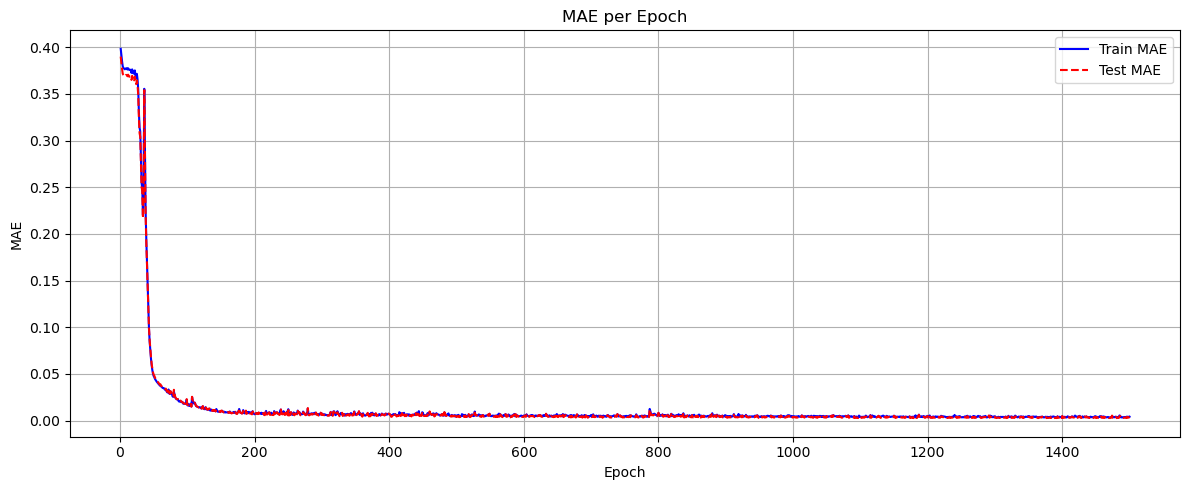

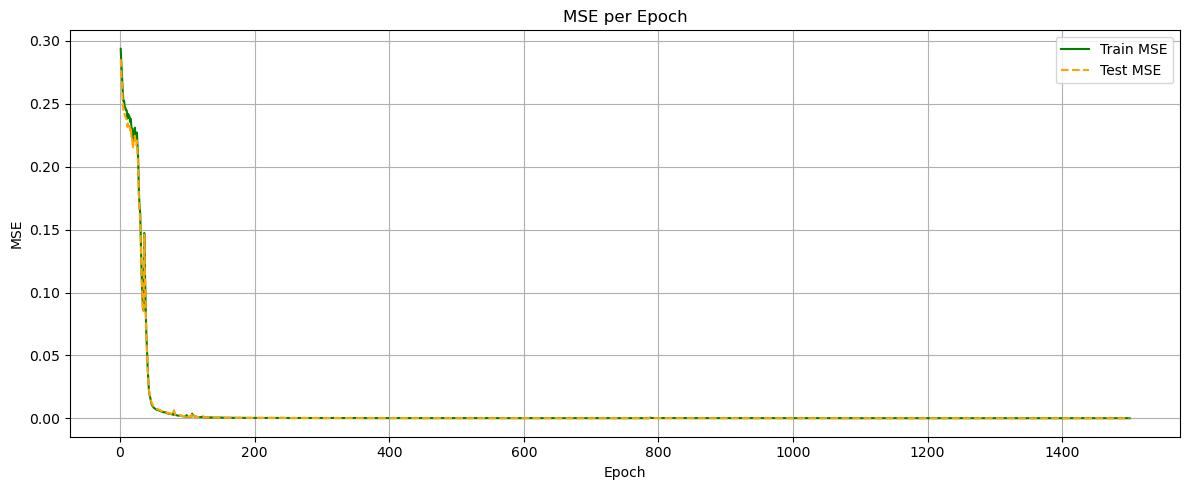

In [21]:
epochs = range(1, N_Epochs + 1)
train_mae_hist = [h[0] for h in train_history]
train_mse_hist = [h[1] for h in train_history]
test_mae_hist = [h[0] for h in test_history]
test_mse_hist = [h[1] for h in test_history]

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mae_hist, label="Train MAE", color="blue")
plt.plot(epochs, test_mae_hist, label="Test MAE", color="red", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("MAE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mse_hist, label="Train MSE", color="green")
plt.plot(epochs, test_mse_hist, label="Test MSE", color="orange", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Full test-set prediction vs ground truth

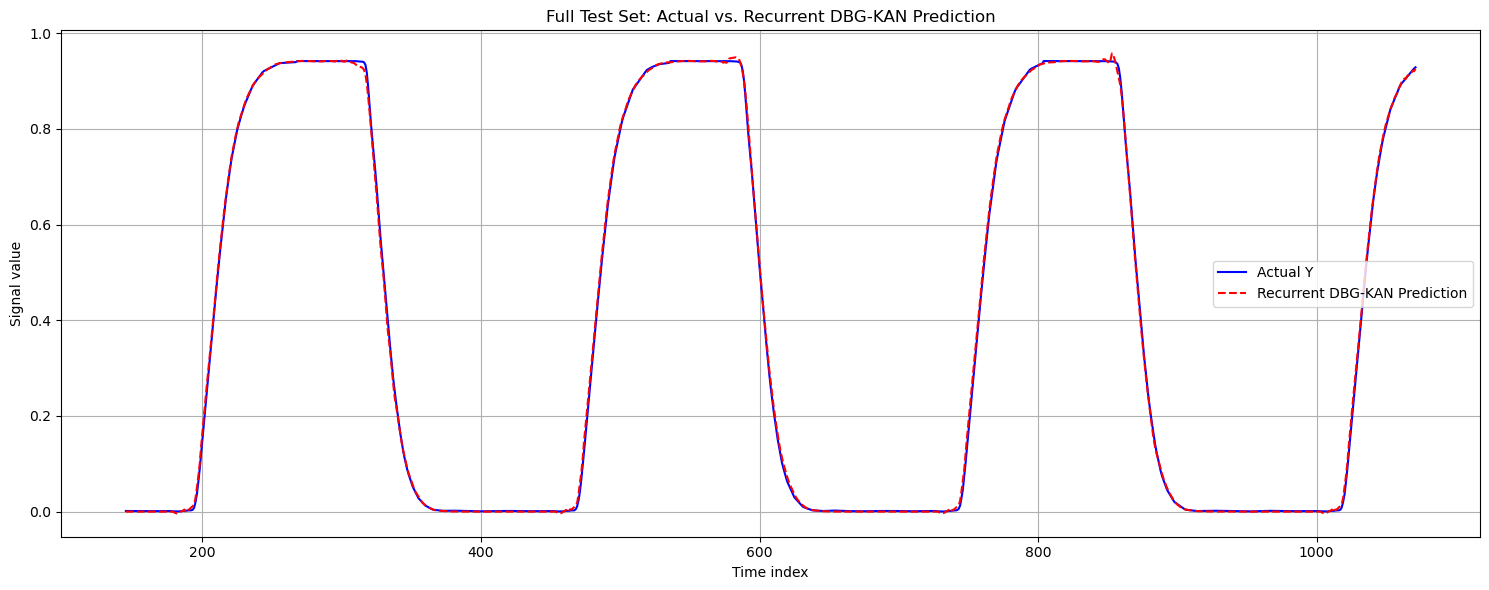

In [22]:
model.eval()
full_predicted_Y_test = np.full_like(Y_test, np.nan, dtype=np.float64)

with torch.no_grad():
    for idx in range(len(test_dataset)):
        x_win, _ = test_dataset[idx]
        x_win = x_win.unsqueeze(0).to(device)
        y_pred_win = model(x_win).cpu().squeeze(0).numpy()

        start_idx = idx + Context_Len
        end_idx = start_idx + Pred_Len
        if start_idx < len(Y_test):
            full_predicted_Y_test[start_idx:min(end_idx, len(Y_test))] = y_pred_win[:min(Pred_Len, len(Y_test) - start_idx)]

start_plot = 145
plt.figure(figsize=(15, 6))
plt.plot(np.arange(start_plot, len(Y_test)), Y_test[start_plot:], label="Actual Y", color="blue")
plt.plot(np.arange(start_plot, len(full_predicted_Y_test)), full_predicted_Y_test[start_plot:],
         label="Recurrent DBG-KAN Prediction", color="red", linestyle="--")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.title("Full Test Set: Actual vs. Recurrent DBG-KAN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()